Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset extracted successfully!

TASK 1: DATASET INFORMATION
Normal images: 3166
Pneumonia images: 8546
Total images: 11712


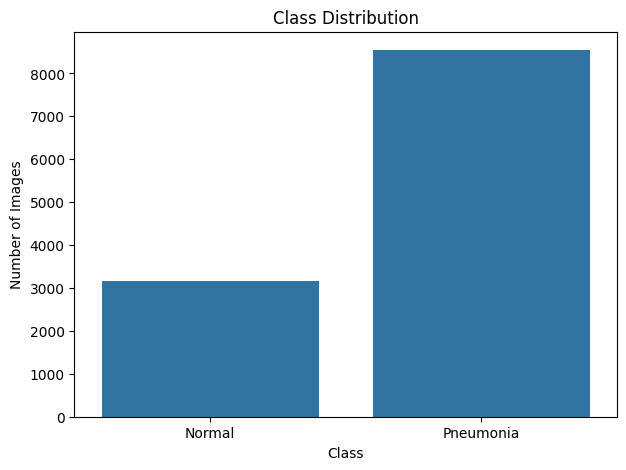

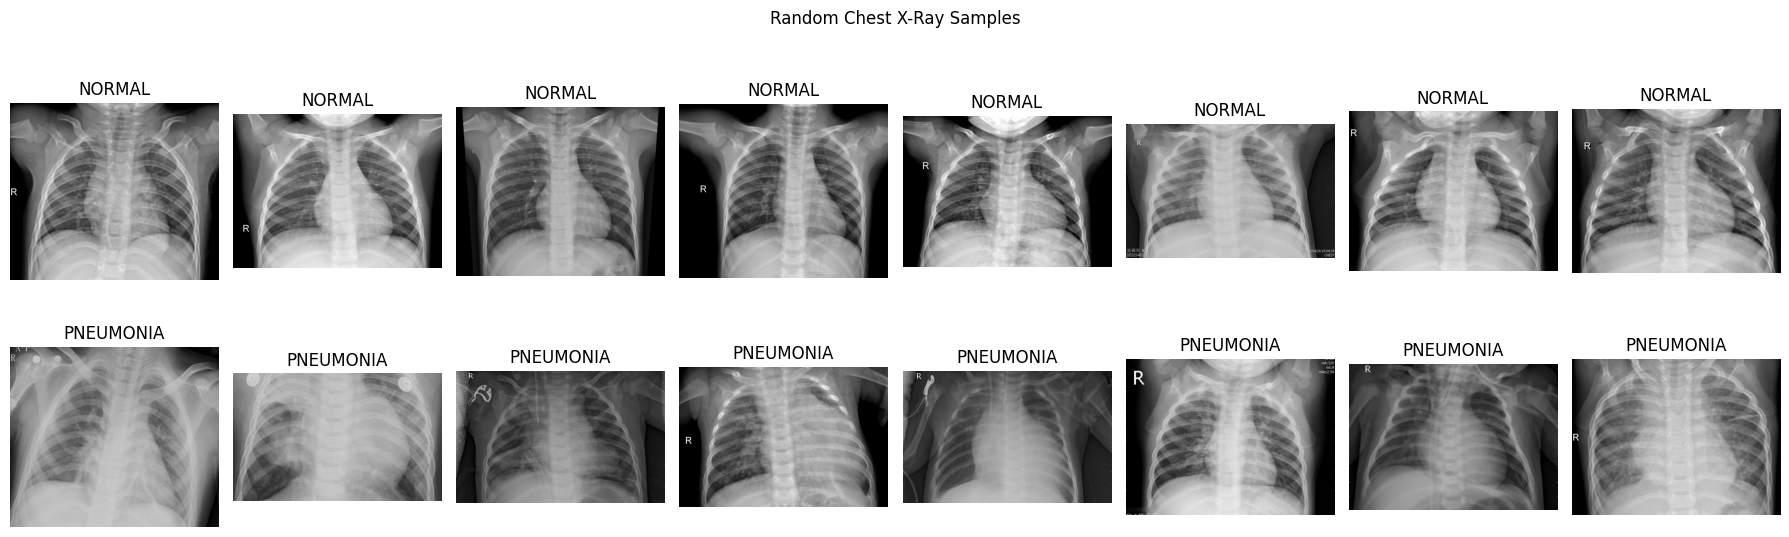


Loading and resizing images...
Processed images: 11712
Image shape: (11712, 128, 128)


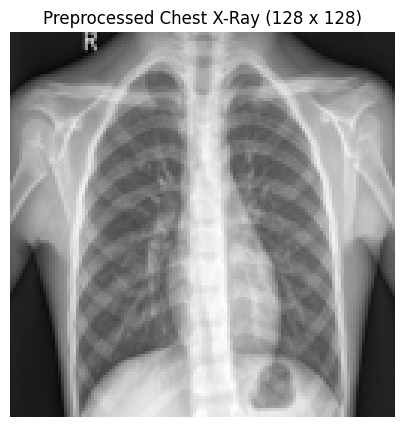


Extracting HOG, LBP and GLCM features...
Features extracted: 500 / 11712
Features extracted: 1000 / 11712
Features extracted: 1500 / 11712
Features extracted: 2000 / 11712
Features extracted: 2500 / 11712
Features extracted: 3000 / 11712
Features extracted: 3500 / 11712
Features extracted: 4000 / 11712
Features extracted: 4500 / 11712
Features extracted: 5000 / 11712
Features extracted: 5500 / 11712
Features extracted: 6000 / 11712
Features extracted: 6500 / 11712
Features extracted: 7000 / 11712
Features extracted: 7500 / 11712
Features extracted: 8000 / 11712
Features extracted: 8500 / 11712
Features extracted: 9000 / 11712
Features extracted: 9500 / 11712
Features extracted: 10000 / 11712
Features extracted: 10500 / 11712
Features extracted: 11000 / 11712
Features extracted: 11500 / 11712

Feature extraction completed!
Feature vector shape: (11712, 1781)

First image feature vector (first 20 values):
[0.03330361 0.0329539  0.0805052  0.2701848  0.05676266 0.00577469
 0.00503878 0.0

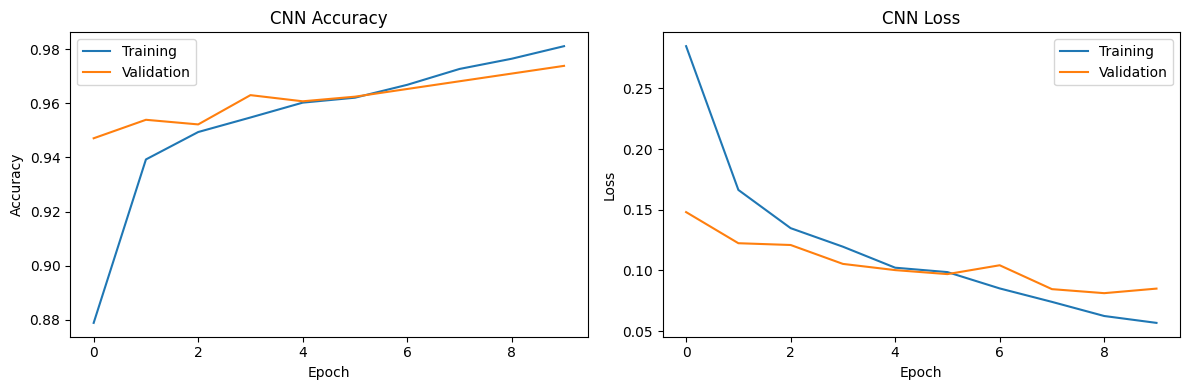

55/55 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step

FINAL TEST RESULTS
Accuracy : 0.9761
Precision: 0.9769
Recall   : 0.9906
F1-score : 0.9837
AUROC    : 0.9967

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.97      0.94      0.95       475
   Pneumonia       0.98      0.99      0.98      1282

    accuracy                           0.98      1757
   macro avg       0.98      0.96      0.97      1757
weighted avg       0.98      0.98      0.98      1757



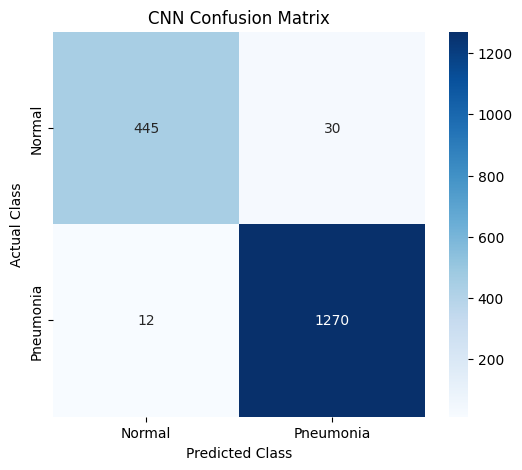


CONFUSION MATRIX INTERPRETATION
True Normal predictions: 445
Normal images predicted as Pneumonia: 30
Pneumonia images predicted as Normal: 12
True Pneumonia predictions: 1270

Misclassification explanation:
False positives are normal X-rays incorrectly classified as pneumonia. False negatives are pneumonia X-rays incorrectly classified as normal. These errors can occur because of similar visual patterns, image quality, or overlapping features.

FINAL MODEL PERFORMANCE


,Metric,Score
0,Accuracy,0.976096
1,Precision,0.976923
2,Recall,0.990640
3,F1-score,0.983734
4,AUROC,0.996729



All requested tasks completed!
Task 1: Dataset exploration and class balance
Task 2: Preprocessing, HOG, LBP, GLCM and data splitting
Task 3: CNN, cross-validation and performance evaluation


In [ ]:
# LAB ASSIGNMENT 6: CNN FOR CHEST X-RAY CLASSIFICATION
# TASK 1, TASK 2 AND TASK 3 ONLY

!pip install -q scikit-image scikit-learn seaborn

import os
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from google.colab import drive
from PIL import Image

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)
# TASK 1: DATA ACQUISITION AND EXPLORATION

# Connect Google Drive
drive.mount('/content/drive')

# CHANGE THIS PATH TO YOUR ACTUAL ZIP FILE NAME
ZIP_PATH = '/content/drive/MyDrive/Untitled folder/archive.zip'

# Extract ZIP only if not already extracted
EXTRACT_PATH = '/content/chest_xray_dataset'

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        "ZIP file not found. Update ZIP_PATH with the correct Google Drive path."
    )

if not os.path.exists(EXTRACT_PATH):
    print("Extracting dataset. This may take some time...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")

# Automatically locate NORMAL and PNEUMONIA folders
root = Path(EXTRACT_PATH)

normal_files = []
pneumonia_files = []

for folder in root.rglob('*'):
    if folder.is_dir() and folder.name.upper() == 'NORMAL':
        normal_files.extend([
            str(f) for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in
            ['.jpg', '.jpeg', '.png']
        ])

    elif folder.is_dir() and folder.name.upper() == 'PNEUMONIA':
        pneumonia_files.extend([
            str(f) for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in
            ['.jpg', '.jpeg', '.png']
        ])

# Remove duplicates
normal_files = sorted(set(normal_files))
pneumonia_files = sorted(set(pneumonia_files))

normal_files = [
    f for f in normal_files
    if '__MACOSX' not in f and '/._' not in f
]

pneumonia_files = [
    f for f in pneumonia_files
    if '__MACOSX' not in f and '/._' not in f
]

if not normal_files or not pneumonia_files:
    raise ValueError(
        "NORMAL/PNEUMONIA folders not found. Check the ZIP structure."
    )

print("\nTASK 1: DATASET INFORMATION")
print("Normal images:", len(normal_files))
print("Pneumonia images:", len(pneumonia_files))
print("Total images:", len(normal_files) + len(pneumonia_files))

# Class balance visualization
plt.figure(figsize=(7, 5))
sns.barplot(
    x=['Normal', 'Pneumonia'],
    y=[len(normal_files), len(pneumonia_files)]
)
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.show()

# Display 8 random images from each class
random.seed(42)

fig, axes = plt.subplots(2, 8, figsize=(18, 6))

for row, (label, image_files) in enumerate([
    ('NORMAL', normal_files),
    ('PNEUMONIA', pneumonia_files)
]):
    samples = random.sample(image_files, min(8, len(image_files)))

    for col, image_path in enumerate(samples):
        image = Image.open(image_path).convert('RGB')
        axes[row, col].imshow(image, cmap='gray')
        axes[row, col].set_title(label)
        axes[row, col].axis('off')

plt.suptitle('Random Chest X-Ray Samples')
plt.tight_layout()
plt.show()


# TASK 2: DATA PREPROCESSING

IMAGE_SIZE = 128

# Prepare image paths and labels
image_paths = normal_files + pneumonia_files
labels = [0] * len(normal_files) + [1] * len(pneumonia_files)

print("\nLoading and resizing images...")

images = []

for i, path in enumerate(image_paths):
    try:
        img = Image.open(path).convert('L')
        img = img.resize((IMAGE_SIZE, IMAGE_SIZE))
        images.append(np.array(img, dtype=np.uint8))

    except Exception as e:
        print("Skipping unreadable image:", path)

        # Keep paths and labels aligned by marking the item
        labels[i] = -1

# Remove unreadable images
valid_indices = [i for i, label in enumerate(labels) if label != -1]

images = np.array(images, dtype=np.uint8)
image_paths = [image_paths[i] for i in valid_indices]
labels = np.array([labels[i] for i in valid_indices])

print("Processed images:", len(images))
print("Image shape:", images.shape)

# Display preprocessed image
plt.figure(figsize=(5, 5))
plt.imshow(images[0], cmap='gray')
plt.title('Preprocessed Chest X-Ray (128 x 128)')
plt.axis('off')
plt.show()

# FEATURE EXTRACTION: HOG, LBP AND GLCM

print("\nExtracting HOG, LBP and GLCM features...")

feature_vectors = []

for i, img in enumerate(images):

    # HOG features
    hog_features = hog(
        img,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        feature_vector=True
    )

    # LBP features
    lbp = local_binary_pattern(
        img,
        P=8,
        R=1,
        method='uniform'
    )

    lbp_hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, 12),
        density=True
    )

    # GLCM features
    glcm = graycomatrix(
        img,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True
    )

    glcm_features = [
        graycoprops(glcm, prop)[0, 0]
        for prop in [
            'contrast',
            'dissimilarity',
            'homogeneity',
            'energy',
            'correlation',
            'ASM'
        ]
    ]

    # Combine all feature vectors
    combined_features = np.concatenate([
        hog_features,
        lbp_hist,
        glcm_features
    ])

    feature_vectors.append(combined_features)

    if (i + 1) % 500 == 0:
        print("Features extracted:", i + 1, "/", len(images))

X_features = np.array(feature_vectors, dtype=np.float32)
y = labels

print("\nFeature extraction completed!")
print("Feature vector shape:", X_features.shape)

# Display feature vector sample
print("\nFirst image feature vector (first 20 values):")
print(X_features[0][:20])

# TRAINING, VALIDATION AND TEST SPLIT: 70 / 15 / 15

indices = np.arange(len(y))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=y
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=y[temp_idx]
)

print("\nDATA SPLIT")
print("Training:", len(train_idx), f"({len(train_idx)/len(y)*100:.1f}%)")
print("Validation:", len(val_idx), f"({len(val_idx)/len(y)*100:.1f}%)")
print("Testing:", len(test_idx), f"({len(test_idx)/len(y)*100:.1f}%)")

# CNN uses grayscale images normalized to 0-1
X_images = images.astype('float32') / 255.0
X_images = X_images[..., np.newaxis]

X_train, y_train = X_images[train_idx], y[train_idx]
X_val, y_val = X_images[val_idx], y[val_idx]
X_test, y_test = X_images[test_idx], y[test_idx]

# Feature vectors are also split for the assignment
X_train_features = X_features[train_idx]
X_val_features = X_features[val_idx]
X_test_features = X_features[test_idx]

print("CNN training images:", X_train.shape)
print("CNN validation images:", X_val.shape)
print("CNN testing images:", X_test.shape)

print("Training feature vectors:", X_train_features.shape)
print("Validation feature vectors:", X_val_features.shape)
print("Testing feature vectors:", X_test_features.shape)


# TASK 3: CNN MODEL TRAINING AND EVALUATION

def create_cnn(filters=32, learning_rate=0.001):

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(128, 128, 1)),

        tf.keras.layers.Conv2D(
            filters, (3, 3), activation='relu'
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(
            filters * 2, (3, 3), activation='relu'
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Conv2D(
            filters * 4, (3, 3), activation='relu'
        ),
        tf.keras.layers.MaxPooling2D((2, 2)),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


# HYPERPARAMETER TUNING USING 3-FOLD CROSS-VALIDATION

print("\nStarting 3-fold cross-validation...")

# Use a subset for faster hyperparameter selection
rng = np.random.RandomState(42)
cv_indices = rng.choice(
    train_idx,
    size=min(1500, len(train_idx)),
    replace=False
)

X_cv = X_images[cv_indices]
y_cv = y[cv_indices]

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

parameter_options = [
    {'filters': 16, 'learning_rate': 0.001},
    {'filters': 32, 'learning_rate': 0.001}
]

best_score = -1
best_params = None

for params in parameter_options:

    fold_scores = []

    for fold, (fit_idx, check_idx) in enumerate(
        skf.split(X_cv, y_cv), start=1
    ):

        tf.keras.backend.clear_session()

        model = create_cnn(
            filters=params['filters'],
            learning_rate=params['learning_rate']
        )

        model.fit(
            X_cv[fit_idx],
            y_cv[fit_idx],
            epochs=2,
            batch_size=32,
            verbose=0
        )

        _, score = model.evaluate(
            X_cv[check_idx],
            y_cv[check_idx],
            verbose=0
        )

        fold_scores.append(score)

        print(
            params,
            "| Fold:", fold,
            "| Accuracy:", round(score, 4)
        )

    mean_score = np.mean(fold_scores)

    print("Mean CV accuracy:", round(mean_score, 4))

    if mean_score > best_score:
        best_score = mean_score
        best_params = params

print("\nBest parameters:", best_params)
print("Best CV accuracy:", round(best_score, 4))


# TRAIN FINAL CNN

tf.keras.backend.clear_session()

model = create_cnn(
    filters=best_params['filters'],
    learning_rate=best_params['learning_rate']
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


# ACCURACY AND LOSS GRAPHS

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# FINAL TEST EVALUATION

probabilities = model.predict(X_test, batch_size=32).ravel()
predictions = (probabilities >= 0.5).astype(int)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, zero_division=0)
recall = recall_score(y_test, predictions, zero_division=0)
f1 = f1_score(y_test, predictions, zero_division=0)

try:
    auroc = roc_auc_score(y_test, probabilities)
except ValueError:
    auroc = float('nan')

print("\nFINAL TEST RESULTS")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))
print("AUROC    :", round(auroc, 4))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=['Normal', 'Pneumonia'],
        zero_division=0
    )
)


# CONFUSION MATRIX

cm = confusion_matrix(
    y_test,
    predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Pneumonia'],
    yticklabels=['Normal', 'Pneumonia']
)

plt.title('CNN Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

tn, fp, fn, tp = cm.ravel()

print("\nCONFUSION MATRIX INTERPRETATION")
print("True Normal predictions:", tn)
print("Normal images predicted as Pneumonia:", fp)
print("Pneumonia images predicted as Normal:", fn)
print("True Pneumonia predictions:", tp)

print("\nMisclassification explanation:")
print(
    "False positives are normal X-rays incorrectly classified as "
    "pneumonia. False negatives are pneumonia X-rays incorrectly "
    "classified as normal. These errors can occur because of similar "
    "visual patterns, image quality, or overlapping features."
)


# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'AUROC'],
    'Score': [accuracy, precision, recall, f1, auroc]
})